### B1: Configuration, contract and time split

All settings live in `configs/train.yaml` (paths, split dates, CV quarters, seed, economics). `src/data.py` loads the contract and refuses to run if transform.joblib and data_spec.json have different contract versions.
- Train: loans issued ≤ 2014-12-31 (14,373; default rate 17.2%). Validation: 2015 (15,627; 20.1%, higher partly because of the in-progress bias on 60-month loans). 2015 is used once, for the final evaluation.
- Tuning uses expanding-window CV by quarter: each fold trains on all loans before a 2014 quarter and validates on that quarter (5,349 / 1,906 → 11,682 / 2,691 loans). Validation starts in 2014 so every fold trains on at least a full year.
- The analytical dataset's SHA-256 fingerprint is recorded with every experiment.

In [1]:
import sys
sys.path.append("..")
import pandas as pd
from src.data import load_config, load_contract, time_split, cv_folds, file_hash, ROOT

cfg = load_config()
tf, spec, data = load_contract(cfg)
train, valid = time_split(data, cfg)
print("contract", spec["contract_version"], "| train", len(train), "| valid", len(valid))
print("default rate train / valid:", round(train[cfg["data"]["target"]].mean(), 3),
      "/", round(valid[cfg["data"]["target"]].mean(), 3))

for q, fit_idx, val_idx in cv_folds(train, cfg):
    print(f"fold {q}: train {len(fit_idx):>6,} | validate {len(val_idx):>5,}")

print("data hash:", file_hash(ROOT / cfg["paths"]["contract_dir"] / "analytical_dataset.parquet")[:16], "...")

contract 1.0.0 | train 14373 | valid 15627
default rate train / valid: 0.172 / 0.201
fold 2014Q1: train  5,349 | validate 1,906
fold 2014Q2: train  7,255 | validate 2,091
fold 2014Q3: train  9,346 | validate 2,336
fold 2014Q4: train 11,682 | validate 2,691
data hash: 9cc2f55230d13567 ...


### B2: Metrics and the benchmark (grade alone)

`src/metrics.py`: AUC (share of defaulter–payer pairs ranked correctly), Gini = 2·AUC − 1 (0 = random, 1 = perfect), KS (largest gap between the share of defaulters and the share of payers declined as the cut-off moves down the ranked list), and Brier score for probabilities. AUC/KS judge ranking only; the cut-off is set later by expected profit, which weighs a missed defaulter (−70%) seven times a lost good customer (+10%).

Grade alone (A=1 … G=7, no training): CV AUC 0.670–0.714 by quarter, mean **0.688**; 2015 AUC **0.703**, KS 0.299. The ±0.02 spread between quarters shows the natural noise of a single-quarter AUC, which is why tuning uses the 4-fold mean.

In [2]:
from src.metrics import ranking_metrics

TARGET = cfg["data"]["target"]
GRADE_NUM = {g: i for i, g in enumerate("ABCDEFG", start=1)}

def evaluate_score(name, score_fn):
    """Score each CV validation quarter and 2015 with score_fn(df) -> risk score; return one row per period."""
    rows = []
    for q, _, val_idx in cv_folds(train, cfg):
        v = train.loc[val_idx]
        rows.append({"model": name, "period": q, **ranking_metrics(v[TARGET], score_fn(v))})
    rows.append({"model": name, "period": "2015", **ranking_metrics(valid[TARGET], score_fn(valid))})
    return pd.DataFrame(rows)

grade_results = evaluate_score("grade alone", lambda df: df["grade"].map(GRADE_NUM))
display(grade_results.round(3))
cv = grade_results[grade_results["period"] != "2015"]
print("CV mean AUC:", round(cv["auc"].mean(), 3), "| 2015 AUC:", round(grade_results.iloc[-1]["auc"], 3))

,model,period,auc,gini,ks
0,grade alone,2014Q1,0.681,0.362,0.281
1,grade alone,2014Q2,0.670,0.340,0.247
2,grade alone,2014Q3,0.688,0.375,0.257
3,grade alone,2014Q4,0.714,0.427,0.310
4,grade alone,2015,0.703,0.405,0.299


CV mean AUC: 0.688 | 2015 AUC: 0.703


### B3: WoE scorecard (logistic regression on the contract's WoE bins)

Feature selection rules, set in advance:
1. IV ≥ 0.02 (contract bins) → 12 weak features dropped (delinquency, public records, account counts; loan_amnt 0.0193 and mort_acc 0.0192 just below).
2. |WoE correlation| ≤ 0.7, keeping the higher-IV feature → tot_hi_cred_lim and tot_cur_bal dropped (vs avg_cur_bal), revol_util dropped (vs bc_util).
3. All weights negative (a safer bin must lower PD) → passed.

14 features. Weights near −1 mean a feature's WoE counts in full (term −0.94, purpose −0.81: unique information); smaller weights mean overlap with other features (verification −0.28).

Tuning (rule: keep a change only if CV AUC improves ≥ 0.002 and weights stay negative): regularization C = 0.1–10 all ≈ 0.703 (C = 0.01 too strong, 0.699) → default C = 1. Adding loan_amnt breaks rule 3 (overlaps loan_to_income); adding mort_acc gives no gain. All runs are in `experiments/log.csv`.

In [3]:
from src.features import MODEL_FEATURES

iv = pd.Series({c: spec["woe_bins"][c]["iv"] for c in MODEL_FEATURES}).sort_values(ascending=False)
woe_train = tf.woe(train)                                     # WoE values from the contract's bins

# Rule 1: IV >= 0.02
rule1 = iv[iv >= 0.02].index.tolist()
print("dropped, IV < 0.02:", {c: round(iv[c], 4) for c in iv.index if c not in rule1})

# Rule 2: greedy by IV, |WoE correlation| <= 0.7 with everything already kept
corr = woe_train[[f"woe_{c}" for c in rule1]].corr().abs()
selected, dropped_corr = [], {}
for c in rule1:                                               # already ordered from highest IV
    clash = [k for k in selected if corr.loc[f"woe_{c}", f"woe_{k}"] > 0.7]
    if clash:
        dropped_corr[c] = f"corr {corr.loc[f'woe_{c}', f'woe_{clash[0]}']:.2f} with {clash[0]}"
    else:
        selected.append(c)
print("dropped, correlated:", dropped_corr)
print(f"\nselected ({len(selected)}):")
print(iv[selected].round(3).to_string())

dropped, IV < 0.02: {'loan_amnt': np.float64(0.0193), 'mort_acc': np.float64(0.0192), 'credit_hist_months': np.float64(0.0115), 'open_acc': np.float64(0.0094), 'revol_bal_log': np.float64(0.0024), 'total_acc': np.float64(0.0023), 'mths_since_last_delinq': np.float64(0.0017), 'ever_delinq': np.float64(0.0014), 'pub_rec': np.float64(0.0009), 'pub_rec_bankruptcies': np.float64(0.0009), 'bc_util_missing': np.float64(0.0008), 'delinq_2yrs': np.float64(0.0)}
dropped, correlated: {'tot_hi_cred_lim_log': 'corr 0.83 with avg_cur_bal_log', 'tot_cur_bal_log': 'corr 0.81 with avg_cur_bal_log', 'revol_util_cap': 'corr 0.76 with bc_util_cap'}

selected (14):
term_months             0.195
fico_mid                0.099
loan_to_income          0.098
acc_open_past_24mths    0.075
dti_cap                 0.062
num_tl_op_past_12m      0.049
verification_grp        0.046
avg_cur_bal_log         0.041
bc_util_cap             0.036
annual_inc_log          0.035
inq_last_6mths          0.033
home_ownership   

In [4]:
from sklearn.linear_model import LogisticRegression

woe_all = tf.woe(data)                       # WoE for every loan (same index as data)
y_all = data[TARGET]

def cv_evaluate(cols, make_model, X=woe_all):
    """Fit on each fold's training part, score its validation quarter; return per-fold metrics + out-of-fold PDs."""
    rows, oof = [], pd.Series(index=train.index, dtype=float)
    for q, fit_idx, val_idx in cv_folds(train, cfg):
        model = make_model().fit(X.loc[fit_idx, cols], y_all.loc[fit_idx])
        p = model.predict_proba(X.loc[val_idx, cols])[:, 1]
        oof.loc[val_idx] = p
        rows.append({"period": q, **ranking_metrics(y_all.loc[val_idx], p)})
    return pd.DataFrame(rows), oof

sc_cols = [f"woe_{c}" for c in selected]
sc_cv, sc_oof = cv_evaluate(sc_cols, lambda: LogisticRegression(max_iter=1000))
display(sc_cv.round(3))
print("scorecard CV mean AUC:", round(sc_cv["auc"].mean(), 3), "| grade CV mean AUC: 0.688")

final_sc = LogisticRegression(max_iter=1000).fit(woe_all.loc[train.index, sc_cols], y_all.loc[train.index])
weights = pd.Series(final_sc.coef_[0], index=selected).round(3).sort_values()
print(weights.to_string())
print("rule 3, all weights negative:", bool((weights < 0).all()))

,period,auc,gini,ks
0,2014Q1,0.700,0.400,0.324
1,2014Q2,0.678,0.355,0.257
2,2014Q3,0.716,0.432,0.335
3,2014Q4,0.718,0.435,0.337


scorecard CV mean AUC: 0.703 | grade CV mean AUC: 0.688
term_months            -0.944
purpose_grp            -0.813
inq_last_6mths         -0.757
acc_open_past_24mths   -0.713
home_ownership         -0.696
bc_util_cap            -0.637
fico_mid               -0.627
annual_inc_log         -0.627
total_rev_hi_lim_log   -0.502
avg_cur_bal_log        -0.479
loan_to_income         -0.439
dti_cap                -0.408
num_tl_op_past_12m     -0.364
verification_grp       -0.281
rule 3, all weights negative: True


In [5]:
variants = []

for C in [0.01, 0.1, 1.0, 10.0]:                                    # 1. regularization
    res, _ = cv_evaluate(sc_cols, lambda C=C: LogisticRegression(C=C, max_iter=1000))
    variants.append({"variant": f"C = {C}", "cv_auc": res["auc"].mean()})

corr_all = woe_all.loc[train.index].corr().abs()
for extra in [["loan_amnt"], ["mort_acc"], ["loan_amnt", "mort_acc"]]:   # 2. borderline features
    cols = sc_cols + [f"woe_{c}" for c in extra]
    res, _ = cv_evaluate(cols, lambda: LogisticRegression(max_iter=1000))
    m = LogisticRegression(max_iter=1000).fit(woe_all.loc[train.index, cols], y_all.loc[train.index])
    max_corr = max(corr_all.loc[f"woe_{c}", sc_cols].max() for c in extra)
    variants.append({"variant": "+ " + " + ".join(extra), "cv_auc": res["auc"].mean(),
                     "all_negative": bool((m.coef_[0] < 0).all()), "max_corr_with_selected": round(max_corr, 2)})

display(pd.DataFrame(variants).round(4))

,variant,cv_auc,all_negative,max_corr_with_selected
0,C = 0.01,0.6993,NaN,NaN
1,C = 0.1,0.7030,NaN,NaN
2,C = 1.0,0.7028,NaN,NaN
3,C = 10.0,0.7027,NaN,NaN
4,+ loan_amnt,0.7024,False,0.57
5,+ mort_acc,0.7028,True,0.52
6,+ loan_amnt + mort_acc,0.7024,True,0.57


In [6]:
from src.experiments import log_experiment

DATA_HASH = file_hash(ROOT / cfg["paths"]["contract_dir"] / "analytical_dataset.parquet")
log = lambda *a, **k: log_experiment(cfg, *a, data_hash=DATA_HASH, contract_version=spec["contract_version"], **k)

grade_cv = grade_results[grade_results["period"] != "2015"]
log("grade_alone", "benchmark", grade_cv, ["grade"], {}, notes="no training; A=1..G=7")
log("scorecard", "base: IV>=0.02, corr<=0.7, C=1", sc_cv, selected, {"C": 1.0},
    notes="all weights negative; chosen")

for C in [0.01, 0.1, 10.0]:
    res, _ = cv_evaluate(sc_cols, lambda C=C: LogisticRegression(C=C, max_iter=1000))
    log("scorecard", f"C={C}", res, selected, {"C": C}, notes="no gain >= 0.002 vs C=1")
for extra, note in [(["loan_amnt"], "weight turned positive (overlaps loan_to_income)"),
                    (["mort_acc"], "no gain"), (["loan_amnt", "mort_acc"], "no gain")]:
    res, _ = cv_evaluate(sc_cols + [f"woe_{c}" for c in extra], lambda: LogisticRegression(max_iter=1000))
    log("scorecard", "+ " + " + ".join(extra), res, selected + extra, {"C": 1.0}, notes=note)

display(pd.read_csv(ROOT / cfg["paths"]["experiment_log"])[["model", "variant", "cv_auc_mean", "cv_ks_mean", "notes"]])

,model,variant,cv_auc_mean,cv_ks_mean,notes
0,grade_alone,benchmark,0.6881,0.2737,no training; A=1..G=7
1,scorecard,"base: IV>=0.02, corr<=0.7, C=1",0.7028,0.3133,all weights negative; chosen
2,scorecard,C=0.01,0.6993,0.3057,no gain >= 0.002 vs C=1
3,scorecard,C=0.1,0.7030,0.3095,no gain >= 0.002 vs C=1
4,scorecard,C=10.0,0.7027,0.3143,no gain >= 0.002 vs C=1
...,...,...,...,...,...
82,scorecard,C=0.1,0.7030,0.3095,no gain >= 0.002 vs C=1
83,scorecard,C=10.0,0.7027,0.3143,no gain >= 0.002 vs C=1
84,scorecard,+ loan_amnt,0.7024,0.3126,weight turned positive (overlaps loan_to_income)
85,scorecard,+ mort_acc,0.7028,0.3130,no gain


### B4: Removing a leak from the scorecard's CV

The contract's WoE values were learned from all 2013–14 loans, including each CV validation quarter, so the scorecard's CV estimate was optimistic. Fix: keep the contract's bin edges but learn each bin's WoE value from the fold's training loans only. CV AUC 0.7028 → **0.6975** (a 0.005 leak). The scorecard still beats grade in every fold (+0.009 on average), by a modest margin.

Lesson: any step that learns from the labels (WoE, target encoding) must be fitted inside each fold. Steps that learn only from features (caps, imputation, the factor model) don't use outcomes and have negligible effect. The contract itself and the final 2015 evaluation are unaffected.

In [7]:
import numpy as np
from src.features import woe_groups

def fold_woe(fit_df, apply_df, cols, rules=spec["woe_bins"]):
    """Contract bin edges, but WoE values learned only from fit_df; unseen bins -> 0."""
    out = pd.DataFrame(index=apply_df.index)
    for c in cols:
        t = pd.crosstab(woe_groups(fit_df[c], rules[c]), fit_df[TARGET])
        good, bad = t[0] + 0.5, t[1] + 0.5
        woe = np.log((good / good.sum()) / (bad / bad.sum()))
        out[f"woe_{c}"] = woe_groups(apply_df[c], rules[c]).map(woe).fillna(0.0).astype(float)
    return out

rows, sc_oof = [], pd.Series(index=train.index, dtype=float)
for q, fit_idx, val_idx in cv_folds(train, cfg):
    fit_df, val_df = train.loc[fit_idx], train.loc[val_idx]
    model = LogisticRegression(max_iter=1000).fit(fold_woe(fit_df, fit_df, selected), fit_df[TARGET])
    p = model.predict_proba(fold_woe(fit_df, val_df, selected))[:, 1]
    sc_oof.loc[val_idx] = p
    rows.append({"period": q, **ranking_metrics(val_df[TARGET], p)})
sc_cv_honest = pd.DataFrame(rows)

display(sc_cv_honest.round(3))
print("CV mean AUC  leaky:", round(sc_cv["auc"].mean(), 4), "| fold-honest:", round(sc_cv_honest["auc"].mean(), 4),
      "| grade: 0.6881")
log("scorecard", "base, WoE values refit per fold (no leakage)", sc_cv_honest, selected, {"C": 1.0},
    notes="replaces the leaky CV estimate; use for comparisons")

,period,auc,gini,ks
0,2014Q1,0.690,0.380,0.304
1,2014Q2,0.673,0.345,0.251
2,2014Q3,0.711,0.423,0.328
3,2014Q4,0.716,0.432,0.328


CV mean AUC  leaky: 0.7028 | fold-honest: 0.6975 | grade: 0.6881


{'timestamp': '2026-11-04T09:40:50',
 'model': 'scorecard',
 'variant': 'base, WoE values refit per fold (no leakage)',
 'cv_auc_mean': np.float64(0.6975),
 'cv_ks_mean': np.float64(0.3025),
 'cv_auc_by_fold': '{"2014Q1": 0.6901, "2014Q2": 0.6727, "2014Q3": 0.7113, "2014Q4": 0.7159}',
 'n_features': 14,
 'features': '["term_months", "fico_mid", "loan_to_income", "acc_open_past_24mths", "dti_cap", "num_tl_op_past_12m", "verification_grp", "avg_cur_bal_log", "bc_util_cap", "annual_inc_log", "inq_last_6mths", "home_ownership", "total_rev_hi_lim_log", "purpose_grp"]',
 'params': '{"C": 1.0}',
 'seed': 42,
 'data_hash': '9cc2f55230d13567',
 'contract_version': '1.0.0',
 'notes': 'replaces the leaky CV estimate; use for comparisons'}

### B5: XGBoost with monotonic constraints

The brief asks for "one stronger model (for example gradient boosting)". XGBoost was chosen for strength on tabular data, built-in monotonic constraints, native missing-value handling, exact per-feature contributions (for reason codes) and fast scoring; LightGBM or CatBoost would be equally valid. Inputs: 26 numeric features plus one-hot columns for the 3 categories (39 columns, category lists fixed by the contract).

Monotonic constraints, each backed by business logic and by the sign of its Spearman correlation with default on 2013–14 loans (all 14 agree):
- PD can only rise with dti, bc_util, revol_util, loan_to_income, inquiries, recent account openings, term
- PD can only fall with fico, income, avg_cur_bal, tot_cur_bal, tot_hi_cred_lim, mort_acc

Untuned (300 trees, depth 3, learning rate 0.05): CV AUC **0.6997 with constraints vs 0.6956 without**. The constraints act as regularization, ruling out noise wiggles, so they improve both explainability and accuracy. XGBoost is only +0.002 above the scorecard (and loses in 2 of 4 folds) before tuning.

In [8]:
import xgboost as xgb

CAT_LEVELS = {"home_ownership": ["MORTGAGE", "OWN", "RENT"],
              "purpose_grp": spec["category_groupings"]["purpose_keep"],
              "verification_grp": ["not_verified", "verified"]}
NUM_FEATS = [c for c in MODEL_FEATURES if c not in CAT_LEVELS]

def xgb_matrix(df):
    """Numeric features as they are + one 0/1 column per category level (fixed lists from the contract)."""
    X = df[NUM_FEATS].astype(float).copy()
    for c, levels in CAT_LEVELS.items():
        for level in levels:
            X[f"{c}={level}"] = (df[c] == level).astype(float)
    return X

MONO_SIGN = {**{c: 1 for c in ["dti_cap", "bc_util_cap", "revol_util_cap", "loan_to_income", "inq_last_6mths",
                                "acc_open_past_24mths", "num_tl_op_past_12m", "term_months"]},
             **{c: -1 for c in ["fico_mid", "annual_inc_log", "avg_cur_bal_log", "tot_cur_bal_log",
                                 "tot_hi_cred_lim_log", "mort_acc"]}}

# 1. Does the data agree with each proposed direction?
check = pd.DataFrame({c: {"proposed": s, "spearman_with_default": train[c].corr(train[TARGET], method="spearman")}
                      for c, s in MONO_SIGN.items()}).T
check["agrees"] = np.sign(check["spearman_with_default"]) == check["proposed"]
display(check.round(3))

# 2. XGBoost with and without the constraints
X_all = xgb_matrix(data)
XCOLS = list(X_all.columns)

def make_xgb(constrained=True):
    mono = tuple(MONO_SIGN.get(c, 0) for c in XCOLS) if constrained else None
    return xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5,
                             subsample=0.8, colsample_bytree=0.8, monotone_constraints=mono,
                             random_state=cfg["seed"], eval_metric="auc")

xgb_cv_c, xgb_oof_c = cv_evaluate(XCOLS, lambda: make_xgb(True), X=X_all)
xgb_cv_u, xgb_oof_u = cv_evaluate(XCOLS, lambda: make_xgb(False), X=X_all)
print("CV mean AUC  constrained:", round(xgb_cv_c["auc"].mean(), 4),
      "| unconstrained:", round(xgb_cv_u["auc"].mean(), 4),
      "| scorecard (honest): 0.6975 | grade: 0.6881")
display(xgb_cv_c.round(3))

params = {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 3, "min_child_weight": 5,
          "subsample": 0.8, "colsample_bytree": 0.8}
_ = log("xgboost", "baseline, monotonic constraints", xgb_cv_c, XCOLS, params, notes="untuned")
_ = log("xgboost", "baseline, no constraints", xgb_cv_u, XCOLS, params, notes="untuned; constraint cost check")

,proposed,spearman_with_default,agrees
dti_cap,1.0,0.096,True
bc_util_cap,1.0,0.075,True
revol_util_cap,1.0,0.060,True
loan_to_income,1.0,0.119,True
inq_last_6mths,1.0,0.067,True
acc_open_past_24mths,1.0,0.107,True
num_tl_op_past_12m,1.0,0.089,True
term_months,1.0,0.176,True
fico_mid,-1.0,-0.112,True
annual_inc_log,-1.0,-0.067,True


CV mean AUC  constrained: 0.6997 | unconstrained: 0.6956 | scorecard (honest): 0.6975 | grade: 0.6881


,period,auc,gini,ks
0,2014Q1,0.685,0.370,0.276
1,2014Q2,0.688,0.375,0.300
2,2014Q3,0.709,0.418,0.316
3,2014Q4,0.717,0.435,0.325


In [9]:
import itertools, time

def make_xgb_p(max_depth, n_estimators, min_child_weight, learning_rate, scale_pos_weight=1.0):
    mono = tuple(MONO_SIGN.get(c, 0) for c in XCOLS)
    return xgb.XGBClassifier(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
                             min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=scale_pos_weight, monotone_constraints=mono,
                             random_state=cfg["seed"], eval_metric="auc")

start, grid = time.time(), []
for lr, d, n, mcw in itertools.product([0.03, 0.05, 0.1], [2, 3, 4], [200, 400, 800], [5, 20]):
    res, _ = cv_evaluate(XCOLS, lambda lr=lr, d=d, n=n, mcw=mcw: make_xgb_p(d, n, mcw, lr), X=X_all)
    grid.append({"learning_rate": lr, "max_depth": d, "n_estimators": n, "min_child_weight": mcw,
                 "cv_auc": res["auc"].mean(), "worst_fold": res["auc"].min()})
    _ = log("xgboost", f"lr={lr}, depth={d}, trees={n}, mcw={mcw}", res, XCOLS,
            {"learning_rate": lr, "max_depth": d, "n_estimators": n, "min_child_weight": mcw}, notes="grid")
grid = pd.DataFrame(grid).sort_values("cv_auc", ascending=False)
print(f"grid done in {time.time() - start:.0f}s")
display(grid.head(10).round(4))

best_auc = grid["cv_auc"].max()
near = grid[grid["cv_auc"] >= best_auc - 0.002].sort_values(["max_depth", "n_estimators", "learning_rate"],
                                                             ascending=[True, True, False])
chosen = near.iloc[0]
print("chosen (simplest within 0.002 of best):",
      chosen[["learning_rate", "max_depth", "n_estimators", "min_child_weight"]].to_dict(),
      "| cv_auc", round(chosen["cv_auc"], 4), "| best", round(best_auc, 4))

ratio = (train[TARGET] == 0).sum() / (train[TARGET] == 1).sum()
lr, d, n, mcw = (float(chosen["learning_rate"]), int(chosen["max_depth"]),
                 int(chosen["n_estimators"]), int(chosen["min_child_weight"]))
res_w, _ = cv_evaluate(XCOLS, lambda: make_xgb_p(d, n, mcw, lr, scale_pos_weight=ratio), X=X_all)
print(f"with scale_pos_weight={ratio:.2f}: cv_auc {res_w['auc'].mean():.4f} vs {chosen['cv_auc']:.4f} without")
_ = log("xgboost", f"chosen + scale_pos_weight={ratio:.2f}", res_w, XCOLS,
        {"learning_rate": lr, "max_depth": d, "n_estimators": n, "min_child_weight": mcw,
         "scale_pos_weight": round(ratio, 2)}, notes="imbalance weighting test")

grid done in 319s


,learning_rate,max_depth,n_estimators,min_child_weight,cv_auc,worst_fold
2,0.03,2,400,5,0.7048,0.6909
18,0.05,2,200,5,0.7038,0.6905
8,0.03,3,400,5,0.7034,0.6922
6,0.03,3,200,5,0.7031,0.6893
3,0.03,2,400,20,0.7031,0.6898
20,0.05,2,400,5,0.7027,0.6902
24,0.05,3,200,5,0.7027,0.6887
4,0.03,2,800,5,0.7026,0.6891
19,0.05,2,200,20,0.7024,0.6877
36,0.10,2,200,5,0.7017,0.6878


chosen (simplest within 0.002 of best): {'learning_rate': 0.05, 'max_depth': 2.0, 'n_estimators': 200.0, 'min_child_weight': 5.0} | cv_auc 0.7038 | best 0.7048
with scale_pos_weight=4.80: cv_auc 0.7029 vs 0.7038 without


In [10]:
edge = []
for lr, n in itertools.product([0.03, 0.05, 0.1], [400, 800]):
    res, _ = cv_evaluate(XCOLS, lambda lr=lr, n=n: make_xgb_p(1, n, 5, lr), X=X_all)
    edge.append({"learning_rate": lr, "max_depth": 1, "n_estimators": n, "cv_auc": res["auc"].mean(),
                 "worst_fold": res["auc"].min()})
    _ = log("xgboost", f"lr={lr}, depth=1, trees={n}, mcw=5", res, XCOLS,
            {"learning_rate": lr, "max_depth": 1, "n_estimators": n, "min_child_weight": 5}, notes="grid edge: stumps")
display(pd.DataFrame(edge).sort_values("cv_auc", ascending=False).round(4))
print("depth-2 chosen: 0.7038 | best of grid: 0.7048 | scorecard: 0.6975")

,learning_rate,max_depth,n_estimators,cv_auc,worst_fold
1,0.03,1,800,0.7073,0.6914
3,0.05,1,800,0.7071,0.6933
2,0.05,1,400,0.7068,0.6901
4,0.10,1,400,0.7064,0.6913
0,0.03,1,400,0.7031,0.6847
5,0.10,1,800,0.7023,0.6863


depth-2 chosen: 0.7038 | best of grid: 0.7048 | scorecard: 0.6975


In [11]:
extra = []
for lr in [0.05, 0.1]:
    res, _ = cv_evaluate(XCOLS, lambda lr=lr: make_xgb_p(1, 200, 5, lr), X=X_all)
    extra.append({"learning_rate": lr, "max_depth": 1, "n_estimators": 200, "cv_auc": res["auc"].mean(),
                  "worst_fold": res["auc"].min()})
    _ = log("xgboost", f"lr={lr}, depth=1, trees=200, mcw=5", res, XCOLS,
            {"learning_rate": lr, "max_depth": 1, "n_estimators": 200, "min_child_weight": 5}, notes="grid edge: fewer trees")
display(pd.DataFrame(extra).round(4))

all_runs = pd.concat([grid, pd.DataFrame(edge), pd.DataFrame(extra)], ignore_index=True)
all_runs["min_child_weight"] = all_runs["min_child_weight"].fillna(5)
best = all_runs["cv_auc"].max()
final = (all_runs[all_runs["cv_auc"] >= best - 0.002]
         .sort_values(["max_depth", "n_estimators", "learning_rate"], ascending=[True, True, False]).iloc[0])
XGB_PARAMS = {"learning_rate": float(final["learning_rate"]), "max_depth": int(final["max_depth"]),
              "n_estimators": int(final["n_estimators"]), "min_child_weight": int(final["min_child_weight"])}
print("best CV AUC:", round(best, 4), "| FINAL XGBoost settings:", XGB_PARAMS, "| cv_auc", round(final["cv_auc"], 4))

,learning_rate,max_depth,n_estimators,cv_auc,worst_fold
0,0.05,1,200,0.7015,0.6829
1,0.10,1,200,0.7065,0.6882


best CV AUC: 0.7073 | FINAL XGBoost settings: {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 200, 'min_child_weight': 5} | cv_auc 0.7065


Results:
- Grid best 0.7048 (depth 2). The top 10 lie within 0.003 (a plateau): shallow trees (depth 2–3) and slow learning (0.03–0.05) dominate, so the exact settings matter little.
- The best sat at the grid's edge (smallest depth), so depth 1 was tested: **depth-1 trees did best (0.7073)**. A depth-1 tree uses one feature at a time, so the model is additive with no interactions; allowing interactions (depth 2–4) slightly hurt, by fitting noise. XGBoost's edge over the scorecard comes from finer per-feature shapes and from using all 39 columns, not from interactions. An additive model also gives clean, exactly additive reason codes.
- **Final settings** (simplest within 0.002 of the best over all 62 runs): learning rate 0.1, depth 1, 200 trees, min_child_weight 5. **CV AUC 0.7065** vs scorecard 0.6975 (+0.009, below the 0.01 rule; 2015 decides) and grade 0.688. Tuning stopped at this plateau.
- `scale_pos_weight = 4.8` (defaulters weighted as if classes were balanced): 0.7029 vs 0.7038 without → not used; the natural default rate is kept, which also keeps probabilities undistorted.

### B7: Calibration

Calibration corrects the level of PDs without changing their order (AUC unchanged). It is learned from out-of-fold predictions (which behave like predictions on new loans) and tested time-aware: for 2014 Q2–Q4, a calibrator is learned on the earlier quarters' out-of-fold PDs and scored on the next quarter (Brier score; lower is better).
- **Scorecard**: none 0.1400 = Platt 0.1400 < isotonic 0.1406. Logistic regression is already calibrated; isotonic fits noise → **no calibration**.
- **XGBoost**: Platt 0.1394 < isotonic 0.1395 < none 0.1397 → **Platt** (beats none; 2 parameters, low risk).
- All methods predict ~16.8–17.1% on average against 18.65% actual: the default rate rises through 2014 into 2015 (partly the in-progress bias), which a calibrator learned on earlier quarters cannot anticipate. Expect PDs to run low on 2015; thresholds tuned on 2015 outcomes partly absorb this, and the gap is reported.

In [12]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

# out-of-fold PDs for the final XGBoost settings (the scorecard's honest ones are in sc_oof)
xgb_cv, xgb_oof = cv_evaluate(XCOLS, lambda: make_xgb_p(XGB_PARAMS["max_depth"], XGB_PARAMS["n_estimators"],
                                                        XGB_PARAMS["min_child_weight"], XGB_PARAMS["learning_rate"]), X=X_all)
_ = log("xgboost", "FINAL settings", xgb_cv, XCOLS, XGB_PARAMS, notes="simplest within 0.002 of best over 62 runs")

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

def fit_calibrator(method, p, y):
    """Return a function raw PD -> calibrated PD, learned from (p, y)."""
    if method == "none":
        return lambda q: np.asarray(q)
    if method == "platt":
        m = LogisticRegression(C=1e6).fit(logit(p), y)
        return lambda q: m.predict_proba(logit(q))[:, 1]
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, y)
    return lambda q: iso.predict(q)

quarter = train["issue_dt"].dt.to_period("Q").astype(str)

def calibration_check(oof, name):
    """Learn each calibrator on earlier quarters' OOF PDs, test on the next quarter (2014 Q2-Q4)."""
    rows = []
    for test_q in ["2014Q2", "2014Q3", "2014Q4"]:
        learn = oof.notna() & (quarter < test_q)
        test = quarter == test_q
        y_test = train.loc[test, TARGET]
        for method in ["none", "platt", "isotonic"]:
            cal = fit_calibrator(method, oof[learn].values, train.loc[learn, TARGET].values)
            p = cal(oof[test].values)
            rows.append({"model": name, "test_quarter": test_q, "method": method,
                         "brier": brier_score_loss(y_test, p), "mean_pd": p.mean(), "actual": y_test.mean()})
    return pd.DataFrame(rows)

cal = pd.concat([calibration_check(sc_oof, "scorecard"), calibration_check(xgb_oof, "xgboost")])
display(cal.groupby(["model", "method"])[["brier", "mean_pd", "actual"]].mean().round(4))

brier  mean_pd  actual
model     method                           
scorecard isotonic  0.1406   0.1685  0.1865
          none      0.1400   0.1683  0.1865
          platt     0.1400   0.1684  0.1865
xgboost   isotonic  0.1395   0.1713  0.1865
          none      0.1397   0.1702  0.1865
          platt     0.1394   0.1711  0.1865

### B8: Ablation (raw fields vs factor scores vs both)

Final XGBoost settings, same 4 CV folds; factor scores constrained by their A7 decile directions (card size unconstrained).
- Raw only (39 columns): CV AUC 0.7065.
- Factors only (4 columns): 0.6342, about two-thirds of the raw features' skill above random, in 4 named profiles. It matches A7's logistic result (0.632).
- Raw + factors (43): 0.7084, +0.0019. Below the 0.002 rule (within noise), so **the final model uses raw features only**.
- Conclusion for the DS: cleaned and engineered features, WoE bins, leakage removal and groupings drive the model; the factor scores are built from the same columns and add interpretation rather than predictive power.

In [13]:
from src.features import FACTOR_SCORE_COLS

FACTOR_SIGN = {"factor_credit_seeking": 1, "factor_card_utilization": 1, "factor_debt_size": -1,
               "factor_card_size": 0}
X_ab = X_all.join(data[FACTOR_SCORE_COLS])

def make_xgb_cols(cols):
    """Final XGBoost settings, with monotonic constraints matched to the given column list."""
    signs = {**MONO_SIGN, **FACTOR_SIGN}
    return xgb.XGBClassifier(**XGB_PARAMS, subsample=0.8, colsample_bytree=0.8,
                             monotone_constraints=tuple(signs.get(c, 0) for c in cols),
                             random_state=cfg["seed"], eval_metric="auc")

ablation = {}
for name, cols in [("raw only", XCOLS), ("factors only", FACTOR_SCORE_COLS),
                   ("raw + factors", XCOLS + FACTOR_SCORE_COLS)]:
    res, _ = cv_evaluate(cols, lambda cols=cols: make_xgb_cols(cols), X=X_ab)
    ablation[name] = {"cv_auc": res["auc"].mean(), "worst_fold": res["auc"].min(), "cv_ks": res["ks"].mean(),
                      "n_columns": len(cols)}
    _ = log("xgboost", f"ablation: {name}", res, cols, XGB_PARAMS, notes="brief ablation")
display(pd.DataFrame(ablation).T.round(4))

,cv_auc,worst_fold,cv_ks,n_columns
raw only,0.7065,0.6882,0.3119,39.0
factors only,0.6342,0.6102,0.2120,4.0
raw + factors,0.7084,0.6924,0.3157,43.0


### B9: Final test on 2015 (used once) and model choice

Fixed before running: scorecard (14 WoE features, C = 1, no calibration) and XGBoost (39 raw columns, lr 0.1, depth 1, 200 trees, monotonic constraints, Platt), both trained on all loans ≤ 2014.

| 2015 | AUC | Gini | KS | Brier | Mean PD | Actual |
| --- | --- | --- | --- | --- | --- | --- |
| Grade alone | 0.7026 | 0.405 | 0.299 | | | |
| Scorecard | 0.7125 | 0.425 | 0.309 | 0.1457 | 17.2% | 20.1% |
| XGBoost | 0.7169 | 0.434 | 0.318 | 0.1442 | 18.8% | 20.1% |

- Both beat grade on unseen loans without using it.
- XGBoost − scorecard = +0.0044 AUC < 0.01 → **the scorecard is the production model** (rule set in DESIGN.md before any model was trained).
- Why the gap is small: tuning reached a plateau, interactions did not help (depth 1 best), and both models share the same weak, additive, monotone features, so the data's information is the ceiling.
- Trade-off recorded: XGBoost's probabilities are closer in level (Brier 0.1442 vs 0.1457); the scorecard under-predicts more (17.2% vs 20.1%), partly due to the rising default rate and in-progress bias. Thresholds are set on 2015 outcomes, and recalibration on recent data is the remedy.

In [14]:
from src.metrics import probability_metrics

# final models: trained on all loans issued <= 2014
sc_model = LogisticRegression(max_iter=1000).fit(woe_all.loc[train.index, sc_cols], y_all.loc[train.index])
xgb_model = make_xgb_cols(XCOLS).fit(X_all.loc[train.index, XCOLS], y_all.loc[train.index])
learn = xgb_oof.notna()
platt = fit_calibrator("platt", xgb_oof[learn].values, train.loc[learn, TARGET].values)

# 2015 predictions
yv = valid[TARGET]
pd_sc = sc_model.predict_proba(woe_all.loc[valid.index, sc_cols])[:, 1]
pd_xgb = platt(xgb_model.predict_proba(X_all.loc[valid.index, XCOLS])[:, 1])

final_2015 = pd.DataFrame({
    "grade alone": ranking_metrics(yv, valid["grade"].map(GRADE_NUM)),
    "scorecard": {**ranking_metrics(yv, pd_sc), **probability_metrics(yv, pd_sc)},
    "xgboost": {**ranking_metrics(yv, pd_xgb), **probability_metrics(yv, pd_xgb)},
}).T
display(final_2015.round(4))

gain = final_2015.loc["xgboost", "auc"] - final_2015.loc["scorecard", "auc"]
CHOSEN = "xgboost" if gain >= 0.01 else "scorecard"
print(f"XGBoost - scorecard 2015 AUC: {gain:+.4f} -> rule (>= 0.01) chooses: {CHOSEN}")

,auc,gini,ks,brier,mean_pd,default_rate
grade alone,0.7026,0.4051,0.2989,NaN,NaN,NaN
scorecard,0.7125,0.4249,0.3093,0.1457,0.1715,0.2009
xgboost,0.7169,0.4338,0.3184,0.1442,0.1876,0.2009


XGBoost - scorecard 2015 AUC: +0.0044 -> rule (>= 0.01) chooses: scorecard


### B10: What would the old model's outputs add? (informational)

Adding grade and int_rate to XGBoost raises CV AUC from 0.7065 to 0.7158 (+0.009): the old model holds information our features lack. They stay excluded: in a live system they are produced by the risk step our model performs (grade = the risk assessment, int_rate = priced from it), and using them would make our model largely a copy of the old one. Logged as informational; the final model is unchanged.

In [15]:
X_old = X_all.join(data[["int_rate"]].astype(float)).assign(grade_num=data["grade"].map(GRADE_NUM).astype(float))
cols_old = XCOLS + ["int_rate", "grade_num"]
MONO_SIGN.update({"int_rate": 1, "grade_num": 1})
res_old, _ = cv_evaluate(cols_old, lambda: make_xgb_cols(cols_old), X=X_old)
print("CV AUC  without old-model inputs:", round(xgb_cv["auc"].mean(), 4),
      "| with grade + int_rate:", round(res_old["auc"].mean(), 4))
_ = log("xgboost", "informational: + grade + int_rate", res_old, cols_old, XGB_PARAMS,
        notes="not used (design decision); measures the cost of independence from the old model")

CV AUC  without old-model inputs: 0.7065 | with grade + int_rate: 0.7158


### B11: Single cut-off from the profit rule, and comparison with grade policies

- Rule: approve if PD < cut-off; repaid loans earn +10% of loan_amnt, defaulted loans lose 70% → break-even PD 12.5%.
- The cut-off is chosen on the 2014 out-of-fold PDs (most profitable): **13.5%**, close to the theoretical 12.5% (2014: 44.8% approved, 8.9% default, +$1.62M). It is applied unchanged to 2015.
- 2015: approving everyone loses $17.0M (−7.5% of volume); the scorecard at 13.5% approves 45.5%, 10.1% default, **+$1.39M**. The best 2015 cut-off in hindsight is 10.5% (+$2.16M): loans scored 10.5% defaulted at about 12.5%, consistent with the under-prediction (17.2% vs 20.1%). Part of this gap is the in-progress bias, which over-counts 2015 defaults.
- Grade policies (approve grades A up to X): 2014 data chooses A–B (+$1.96M on 2014). Applied to 2015, A–B approves 47.8%, 10.0% default, **+$1.66M**, ahead of the scorecard's +$1.39M.
- At equal volume (19% of 2015), grade A defaults 5.0% vs 6.5% for the scorecard's safest loans (59% overlap): grade is better at picking the safest loans, although the scorecard ranks the whole list better (AUC 0.7125 vs 0.7026).
- Inside grade A the scorecard still separates risk (AUC 0.60; default 2.8% / 5.2% / 7.0% by PD third), so it carries information grade lacks.
- Likely reasons: Lending Club's model holds information we don't (grade + int_rate add +0.009 CV AUC, B10); a better grade gets a lower interest rate, which itself lowers default; and the brief's flat +10% gain ignores that safer grades pay less interest. Grade stays excluded by design (B10); this result is reported in the model card.

,approval_rate,default_rate_approved,profit_$M,return_on_approved
approve everyone,1.000,0.201,-17.030,-0.075
"best grade policy (A-A, hindsight)",0.190,0.050,2.571,0.060
"scorecard, cut-off 0.135 (chosen on 2014)",0.455,0.101,1.393,0.014
"scorecard, cut-off 0.105 (2015 hindsight)",0.311,0.082,2.162,0.031


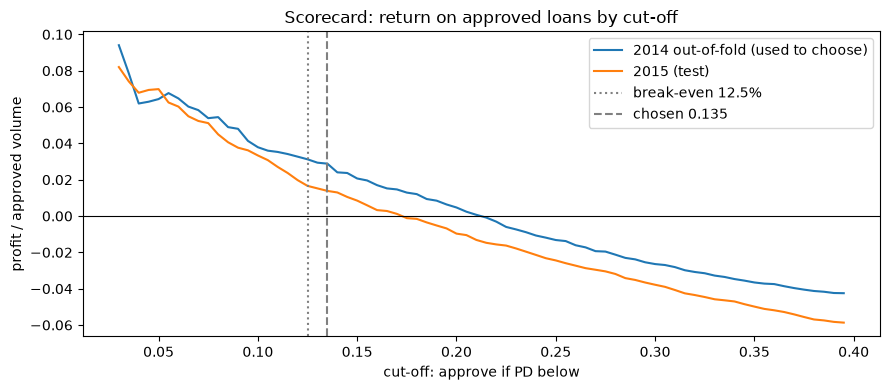

In [16]:
import matplotlib.pyplot as plt

GAIN, LOSS = cfg["economics"]["gain_if_repaid"], cfg["economics"]["loss_if_default"]

def policy_result(approve, y, amount):
    """Realized profit of approving the loans where approve is True."""
    approve, y, amount = np.asarray(approve), np.asarray(y), np.asarray(amount)
    pnl = np.where(y == 1, -LOSS, GAIN) * amount
    vol = amount[approve].sum()
    return {"approval_rate": approve.mean(),
            "default_rate_approved": y[approve].mean() if approve.any() else np.nan,
            "profit_$M": pnl[approve].sum() / 1e6,
            "return_on_approved": pnl[approve].sum() / vol if vol else np.nan}

cuts = np.round(np.arange(0.03, 0.40, 0.005), 3)
m = sc_oof.notna()
cv_curve = pd.DataFrame([policy_result(sc_oof[m] < c, train.loc[m, TARGET], train.loc[m, "loan_amnt"]) for c in cuts], index=cuts)
v_curve = pd.DataFrame([policy_result(pd_sc < c, valid[TARGET], valid["loan_amnt"]) for c in cuts], index=cuts)
CUT = float(cv_curve["profit_$M"].idxmax())             # chosen on 2014 out-of-fold PDs
cut_hindsight = float(v_curve["profit_$M"].idxmax())    # what 2015 hindsight would pick

yv, amt, grades = valid[TARGET].values, valid["loan_amnt"].values, valid["grade"].values
grade_best = max(((g, policy_result(np.isin(grades, list("ABCDEFG")[:i + 1]), yv, amt)) for i, g in enumerate("ABCDEFG")),
                 key=lambda x: x[1]["profit_$M"])
results = pd.DataFrame({
    "approve everyone": policy_result(np.ones(len(yv), bool), yv, amt),
    f"best grade policy (A-{grade_best[0]}, hindsight)": grade_best[1],
    f"scorecard, cut-off {CUT:.3f} (chosen on 2014)": policy_result(pd_sc < CUT, yv, amt),
    f"scorecard, cut-off {cut_hindsight:.3f} (2015 hindsight)": policy_result(pd_sc < cut_hindsight, yv, amt),
}).T
display(results.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cuts, cv_curve["return_on_approved"], label="2014 out-of-fold (used to choose)")
ax.plot(cuts, v_curve["return_on_approved"], label="2015 (test)")
for x, style, lab in [(0.125, ":", "break-even 12.5%"), (CUT, "--", f"chosen {CUT:.3f}")]:
    ax.axvline(x, linestyle=style, color="grey", label=lab)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("cut-off: approve if PD below"); ax.set_ylabel("profit / approved volume")
ax.set_title("Scorecard: return on approved loans by cut-off"); ax.legend(); plt.tight_layout()
fig.savefig("../reports/b_cutoff_profit.png", dpi=120, bbox_inches="tight"); plt.show()

In [17]:
# 1. Which grade policy would 2014 have chosen? (no hindsight)
g14 = train.loc[m, "grade"].values
y14, a14 = train.loc[m, TARGET].values, train.loc[m, "loan_amnt"].values
grade_2014 = pd.DataFrame({f"A-{g}": policy_result(np.isin(g14, list("ABCDEFG")[:i + 1]), y14, a14)
                           for i, g in enumerate("ABCDEFG")}).T
print("Grade policies on 2014 (to choose without hindsight):")
display(grade_2014.round(3))

# 2. Same volume: the scorecard's safest loans vs grade A, on 2015
is_A = grades == "A"
k = is_A.sum()
top_k = np.zeros(len(pd_sc), bool)
top_k[np.argsort(pd_sc)[:k]] = True
same_vol = pd.DataFrame({"grade A": policy_result(is_A, yv, amt),
                         f"scorecard's safest {k} loans": policy_result(top_k, yv, amt)}).T
print("Same number of approvals, 2015:")
display(same_vol.round(3))
print("share of the scorecard's safest loans that are grade A:", round((top_k & is_A).sum() / k, 3))

# 3. Inside grade A: does the scorecard still separate risk?
print("AUC inside grade A (2015):", round(ranking_metrics(yv[is_A], pd_sc[is_A])["auc"], 4))
inside = pd.DataFrame({"pd": pd_sc[is_A], "y": yv[is_A]})
inside["third"] = pd.qcut(inside["pd"], 3, labels=["safest third", "middle third", "riskiest third"])
display(inside.groupby("third", observed=True)["y"].agg(n="size", default_rate="mean").round(3))

Grade policies on 2014 (to choose without hindsight):


,approval_rate,default_rate_approved,profit_$M,return_on_approved
A-A,0.162,0.044,1.412,0.067
A-B,0.423,0.084,1.956,0.037
A-C,0.708,0.127,-0.005,-0.000
A-D,0.881,0.152,-2.626,-0.023
A-E,0.966,0.171,-5.277,-0.042
A-F,0.993,0.177,-6.261,-0.048
A-G,1.000,0.180,-6.791,-0.052


Same number of approvals, 2015:


,approval_rate,default_rate_approved,profit_$M,return_on_approved
grade A,0.19,0.050,2.571,0.060
scorecard's safest 2970 loans,0.19,0.065,1.975,0.045


share of the scorecard's safest loans that are grade A: 0.594
AUC inside grade A (2015): 0.6014


,n,default_rate
third,,
safest third,990,0.028
middle third,990,0.052
riskiest third,990,0.070


In [18]:
print("scorecard at CUT, 2014 out-of-fold:", cv_curve.loc[CUT].round(3).to_dict())
r = policy_result(np.isin(grades, ["A", "B"]), yv, amt)
print("grade A-B (the policy 2014 would choose), applied to 2015:", {k: round(v, 3) for k, v in r.items()})

scorecard at CUT, 2014 out-of-fold: {'approval_rate': 0.448, 'default_rate_approved': 0.089, 'profit_$M': 1.62, 'return_on_approved': 0.029}
grade A-B (the policy 2014 would choose), applied to 2015: {'approval_rate': np.float64(0.478), 'default_rate_approved': np.float64(0.1), 'profit_$M': np.float64(1.661), 'return_on_approved': np.float64(0.016)}


### B12: Decision policy: three bands

- Assumption: the review team can handle about 10% of applications, centred on the cut-off (5% each side), chosen on the 2014 out-of-fold PDs.
- **Auto-approve PD < 12.4% · manual review 12.4–14.7% · auto-decline PD ≥ 14.7%.** T1 lands on the theoretical break-even (12.5%).

| Band | 2014 share | 2014 default | 2015 share | 2015 default | 2015 profit if all approved |
| --- | --- | --- | --- | --- | --- |
| Auto-approve | 39.8% | 8.5% | 40.3% | 9.7% | +$1.51M |
| Review | 10.0% | 15.0% | 10.3% | 14.4% | −$0.42M |
| Auto-decline | 50.2% | 26.1% | 49.4% | 29.8% | −$18.1M |

- Default rates rise across the bands, and the review band holds about 10% in both years.
- The review band is the uncertain zone: its default rate sits just above break-even, so approving all of it loses a little (−1.5% of volume in 2014, −2.0% in 2015). Reviewers should approve only applications their checks improve.
- 2015 profit ranges from +$1.51M (reviewers decline all; 40.3% approved) to +$1.09M (reviewers approve all; 50.6% approved). The auto-approve band alone beats the single cut-off (+$1.39M) because the 12.4–13.5% slice, which lost money in 2015, now goes to review.
- Every band defaults more in 2015 than in 2014 (drift, plus the in-progress bias). The thresholds stay at the 2014-chosen values rather than being re-fitted on biased 2015 labels; refresh them once 2015 loans mature, and monitor quarterly.

In [19]:
REVIEW_SHARE = 0.10   # assumption: the review team can handle about 10% of applications

q_cut = (sc_oof[m] < CUT).mean()                       # share of 2014 loans below the cut-off
T1 = float(np.quantile(sc_oof[m], q_cut - REVIEW_SHARE / 2))
T2 = float(np.quantile(sc_oof[m], q_cut + REVIEW_SHARE / 2))
print(f"T1 (auto-approve below) = {T1:.3f} | CUT = {CUT:.3f} | T2 (auto-decline from) = {T2:.3f}")

def band(p, t1=T1, t2=T2):
    """1 = auto-approve, 2 = manual review, 3 = auto-decline."""
    p = np.asarray(p)
    return np.where(p < t1, "1 auto-approve", np.where(p < t2, "2 review", "3 auto-decline"))

def band_table(p, y, amount):
    """Share of applications, default rate, and profit if every loan in the band were approved."""
    y, amount = np.asarray(y), np.asarray(amount)
    df = pd.DataFrame({"band": band(p), "y": y, "amt": amount,
                       "pnl": np.where(y == 1, -LOSS, GAIN) * amount})
    t = df.groupby("band").agg(n=("y", "size"), default_rate=("y", "mean"),
                               profit_if_approved_M=("pnl", "sum"), volume=("amt", "sum"))
    t["share"] = t["n"] / len(df)
    t["return_if_approved"] = t["profit_if_approved_M"] / t["volume"]
    t["profit_if_approved_M"] = t["profit_if_approved_M"] / 1e6
    return t[["n", "share", "default_rate", "profit_if_approved_M", "return_if_approved"]]

print("2014 out-of-fold (used to choose):")
display(band_table(sc_oof[m], train.loc[m, TARGET], train.loc[m, "loan_amnt"]).round(3))
print("2015 (test):")
display(band_table(pd_sc, yv, amt).round(3))

T1 (auto-approve below) = 0.124 | CUT = 0.135 | T2 (auto-decline from) = 0.147
2014 out-of-fold (used to choose):


,n,share,default_rate,profit_if_approved_M,return_if_approved
band,,,,,
1 auto-approve,3596,0.398,0.085,1.550,0.031
2 review,902,0.100,0.150,-0.180,-0.015
3 auto-decline,4526,0.502,0.261,-8.161,-0.119


2015 (test):


,n,share,default_rate,profit_if_approved_M,return_if_approved
band,,,,,
1 auto-approve,6292,0.403,0.097,1.508,0.017
2 review,1613,0.103,0.144,-0.416,-0.020
3 auto-decline,7722,0.494,0.298,-18.123,-0.155


In [20]:
def psi(expected, actual, n_bins=10, eps=1e-4):
    """Population Stability Index of `actual` vs `expected`; bins = deciles of expected."""
    inner = np.quantile(expected, np.linspace(0, 1, n_bins + 1)[1:-1])
    e = np.bincount(np.searchsorted(inner, expected, side="right"), minlength=n_bins) / len(expected)
    a = np.bincount(np.searchsorted(inner, actual, side="right"), minlength=n_bins) / len(actual)
    e, a = np.clip(e, eps, None), np.clip(a, eps, None)
    return float(((a - e) * np.log(a / e)).sum())

pd_train = sc_model.predict_proba(woe_all.loc[train.index, sc_cols])[:, 1]   # 2013-14 PDs: the stability reference
gnum = valid["grade"].map(GRADE_NUM).values
quarter = valid["issue_dt"].dt.to_period("Q").astype(str).values

rows = {}
for qt in sorted(set(quarter)):
    s = quarter == qt
    r = ranking_metrics(yv[s], pd_sc[s])
    rows[qt] = {"n": int(s.sum()), "auc": r["auc"], "ks": r["ks"],
                "grade_auc": ranking_metrics(yv[s], gnum[s])["auc"],
                "brier": probability_metrics(yv[s], pd_sc[s])["brier"],
                "mean_pd": pd_sc[s].mean(), "default_rate": yv[s].mean(),
                "psi_pd_vs_2014": psi(pd_train, pd_sc[s])}
by_q = pd.DataFrame(rows).T
display(by_q.round(4))
by_q.to_csv("../reports/b_by_quarter_2015.csv")

,n,auc,ks,grade_auc,brier,mean_pd,default_rate,psi_pd_vs_2014
2015Q1,3249.0,0.6930,0.2983,0.6830,0.1502,0.1788,0.2053,0.0050
2015Q2,3463.0,0.7191,0.3310,0.7132,0.1430,0.1765,0.1958,0.0040
2015Q3,4069.0,0.7158,0.3124,0.7149,0.1470,0.1669,0.2035,0.0106
2015Q4,4846.0,0.7179,0.3132,0.6983,0.1436,0.1667,0.1993,0.0059


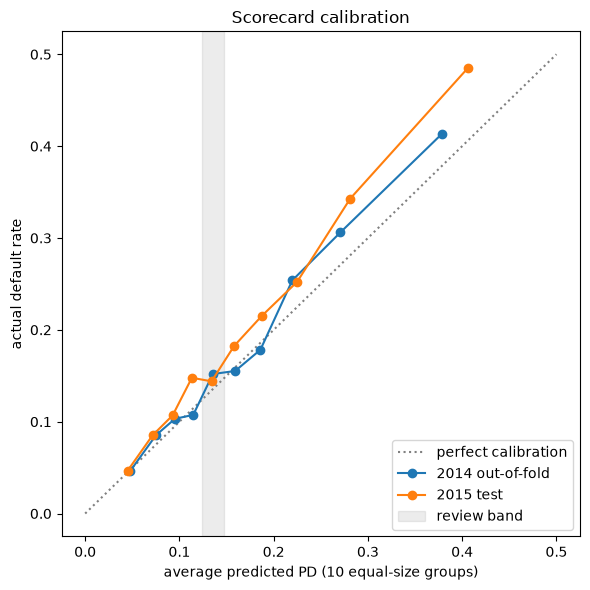

In [21]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 0.5], [0, 0.5], ":", color="grey", label="perfect calibration")
for name, y_, p_ in [("2014 out-of-fold", train.loc[m, TARGET], sc_oof[m]), ("2015 test", yv, pd_sc)]:
    actual, predicted = calibration_curve(y_, p_, n_bins=10, strategy="quantile")
    ax.plot(predicted, actual, "o-", label=name)
ax.axvspan(T1, T2, color="grey", alpha=0.15, label="review band")
ax.set_xlabel("average predicted PD (10 equal-size groups)"); ax.set_ylabel("actual default rate")
ax.set_title("Scorecard calibration"); ax.legend(); plt.tight_layout()
fig.savefig("../reports/b_calibration.png", dpi=120, bbox_inches="tight"); plt.show()

### B14: Outcomes by region and income band (2015)

States grouped into the 4 US Census regions (a standard, neutral grouping with large groups); income in fixed bands. Location is not a model input; this checks whether the model still treats groups differently.

- **Regions:** auto-approval 37–42%; default among approved 8.6–10.2% with overlapping 95% CIs; calibration gap (actual − PD) 2.4–3.9 points vs 2.9 overall. Northeast is highest (3.9), within noise (±1.4) but consistent with A7's NY finding → monitor.
- **Income:** auto-approval rises with income (22% for < 40k → 65% for 120k+), as expected from income and loan_to_income in the model. Gaps for < 40k to 80–120k are 2.0–3.1 points (near average), so lower incomes are not treated unfairly.
- **Failure segment: 120k+.** Predicted 11.8% vs actual 17.8% (gap 6.1 points, far beyond the ±1.7 noise). Approved high earners default at 11.3% (CI 9.6–13.1), as often as the lowest band and more than 60–120k (8.2–8.5%). Hypotheses: inflated self-reported income (A4 rated income medium reliability), larger loans and debt not fully captured by 5 WoE bins, and the accepted-only bias. Tested in the error analysis (B15).

In [22]:
from statsmodels.stats.proportion import proportion_confint

REGION = {**dict.fromkeys(["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"], "Northeast"),
          **dict.fromkeys(["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"], "Midwest"),
          **dict.fromkeys(["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV", "AL", "KY", "MS", "TN",
                           "AR", "LA", "OK", "TX"], "South"),
          **dict.fromkeys(["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY", "AK", "CA", "HI", "OR", "WA"], "West")}
INCOME_EDGES = [0, 40_000, 60_000, 80_000, 120_000, np.inf]
INCOME_LABELS = ["< 40k", "40-60k", "60-80k", "80-120k", "120k +"]

def outcomes_by(groups, p, y):
    """Per group: decision rates, default rate among auto-approved (95% Wilson CI), mean PD vs actual."""
    df = pd.DataFrame({"g": np.asarray(groups), "band": band(p), "pd": np.asarray(p), "y": np.asarray(y)})
    rows = {}
    for g, d in df.groupby("g", observed=True):
        appr = d["band"] == "1 auto-approve"
        lo, hi = proportion_confint(d.loc[appr, "y"].sum(), appr.sum(), method="wilson")
        rows[g] = {"n": len(d), "approve_rate": appr.mean(), "review_rate": (d["band"] == "2 review").mean(),
                   "default_approved": d.loc[appr, "y"].mean(), "ci_low": lo, "ci_high": hi,
                   "mean_pd": d["pd"].mean(), "default_all": d["y"].mean(),
                   "gap_actual_minus_pd": d["y"].mean() - d["pd"].mean()}
    return pd.DataFrame(rows).T

region = valid["addr_state_clean"].map(REGION).fillna("unknown")
income_band = pd.cut(valid["annual_inc"], INCOME_EDGES, labels=INCOME_LABELS, right=False)

by_region = outcomes_by(region, pd_sc, yv)
by_income = outcomes_by(income_band, pd_sc, yv)
print("2015 by region:"); display(by_region.round(3))
print("2015 by income band:"); display(by_income.round(3))
by_region.to_csv("../reports/b_by_region_2015.csv"); by_income.to_csv("../reports/b_by_income_2015.csv")

2015 by region:


,n,approve_rate,review_rate,default_approved,ci_low,ci_high,mean_pd,default_all,gap_actual_minus_pd
Midwest,2784.0,0.374,0.099,0.086,0.071,0.105,0.179,0.207,0.028
Northeast,3152.0,0.424,0.107,0.102,0.087,0.119,0.167,0.206,0.039
South,5682.0,0.402,0.102,0.100,0.088,0.113,0.172,0.200,0.028
West,4009.0,0.407,0.105,0.094,0.081,0.110,0.170,0.194,0.024


2015 by income band:


,n,approve_rate,review_rate,default_approved,ci_low,ci_high,mean_pd,default_all,gap_actual_minus_pd
120k +,1962.0,0.651,0.082,0.113,0.096,0.131,0.118,0.178,0.061
40-60k,4077.0,0.324,0.114,0.105,0.090,0.123,0.190,0.215,0.025
60-80k,3549.0,0.401,0.098,0.082,0.069,0.098,0.174,0.195,0.020
80-120k,3479.0,0.492,0.099,0.085,0.072,0.099,0.152,0.177,0.025
< 40k,2560.0,0.218,0.116,0.113,0.089,0.142,0.205,0.236,0.031


### B15: Error analysis: segments with poor calibration (2015)

For each segment (≥ 300 loans): mean PD vs actual default rate (95% Wilson CI). Flagged if even the CI's low end exceeds the PD by more than the overall gap (2.9 points), or the CI's high end is below the PD.
- **60-month loans**: PD 28.8% vs actual 36.4% (gap 7.6; 36-month: 1.4). A quarter of the loans, but about two-thirds of the total under-prediction. Consistent with the in-progress bias: 2015 60-month loans could not finish by the March 2019 snapshot, so only defaults and early payoffs remain. This is mainly a label problem; remedy: recalibrate once these loans mature.
- **Income 120k+**: gap 6.1, identical for verified (n = 1,600) and not-verified (n = 362) income → the inflated-income hypothesis is rejected. Tested next: whether it comes from term.
- **Purpose "other"** (merged rare purposes): gap 5.6 (flagged); home improvement 4.9 (not flagged, wide CI).
- No segment is over-predicted. FICO bands, home ownership and verification are close to the overall gap (1.6–4.2).
- Feature ideas from this analysis (overall utilization, card debt ÷ income, income × term, finer purpose groups) are listed as next steps in the model card. They were not added: a contract change, likely +0.001–0.005 AUC, and they could no longer be tested cleanly on 2015.

In [23]:
def calib_by(groups, p, y, min_n=300):
    """Per group (n >= min_n): mean PD, actual default rate with 95% Wilson CI, gap."""
    df = pd.DataFrame({"g": np.asarray(groups), "pd": np.asarray(p), "y": np.asarray(y)})
    rows = {}
    for g, d in df.groupby("g", observed=True):
        if len(d) < min_n:
            continue
        lo, hi = proportion_confint(d["y"].sum(), len(d), method="wilson")
        rows[g] = {"n": len(d), "mean_pd": d["pd"].mean(), "actual": d["y"].mean(),
                   "ci_low": lo, "ci_high": hi, "gap": d["y"].mean() - d["pd"].mean()}
    return pd.DataFrame(rows).T

OVERALL_GAP = yv.mean() - pd_sc.mean()
fico_band = pd.cut(valid["fico_mid"], [0, 680, 700, 720, 750, 900],
                   labels=["< 680", "680-700", "700-720", "720-750", "750 +"], right=False)
segments = {"term": valid["term_months"], "purpose": valid["purpose_grp"],
            "home_ownership": valid["home_ownership"], "verification": valid["verification_grp"],
            "fico_band": fico_band, "income_band": income_band,
            "income x verification": income_band.astype(str) + " | " + valid["verification_grp"].astype(str)}

tables = []
for name, g in segments.items():
    t = calib_by(g, pd_sc, yv)
    t.insert(0, "segment", name)
    tables.append(t)
seg = pd.concat(tables)
seg["extra_gap"] = seg["gap"] - OVERALL_GAP
seg["flag"] = np.where(seg["ci_low"] - seg["mean_pd"] > OVERALL_GAP, "UNDER-predicted beyond drift",
                       np.where(seg["ci_high"] < seg["mean_pd"], "OVER-predicted", ""))
print(f"overall gap (actual - PD): {OVERALL_GAP:.3f}")
display(seg.sort_values("extra_gap", ascending=False).round(3))
seg.to_csv("../reports/b_calibration_segments_2015.csv")

overall gap (actual - PD): 0.029


,segment,n,mean_pd,actual,ci_low,ci_high,gap,extra_gap,flag
60,term,3844.0,0.288,0.364,0.349,0.379,0.076,0.046,UNDER-predicted beyond drift
120k + | not_verified,income x verification,362.0,0.080,0.141,0.109,0.181,0.061,0.032,
120k +,income_band,1962.0,0.118,0.178,0.162,0.196,0.061,0.031,UNDER-predicted beyond drift
120k + | verified,income x verification,1600.0,0.126,0.187,0.169,0.207,0.061,0.031,UNDER-predicted beyond drift
other,purpose,1048.0,0.166,0.222,0.198,0.248,0.056,0.027,UNDER-predicted beyond drift
home_improvement,purpose,937.0,0.127,0.176,0.153,0.202,0.049,0.020,
680-700,fico_band,4283.0,0.182,0.224,0.211,0.236,0.042,0.012,
OWN,home_ownership,1708.0,0.170,0.207,0.188,0.227,0.037,0.008,
< 40k | verified,income x verification,1907.0,0.222,0.257,0.238,0.278,0.036,0.006,
verified,verification,11386.0,0.187,0.222,0.214,0.229,0.034,0.005,


In [24]:
it = calib_by(income_band.astype(str) + " | " + valid["term_months"].astype(int).astype(str) + "m", pd_sc, yv)
display(it.round(3))

,n,mean_pd,actual,ci_low,ci_high,gap
120k + | 36m,1429.0,0.084,0.129,0.113,0.148,0.046
120k + | 60m,533.0,0.209,0.310,0.272,0.350,0.101
40-60k | 36m,3138.0,0.147,0.153,0.140,0.166,0.005
40-60k | 60m,939.0,0.333,0.423,0.392,0.455,0.090
60-80k | 36m,2589.0,0.129,0.134,0.122,0.148,0.005
60-80k | 60m,960.0,0.297,0.357,0.328,0.388,0.061
80-120k | 36m,2400.0,0.108,0.116,0.104,0.130,0.009
80-120k | 60m,1079.0,0.251,0.313,0.286,0.342,0.062
< 40k | 36m,2227.0,0.178,0.202,0.185,0.219,0.024
< 40k | 60m,333.0,0.388,0.468,0.416,0.522,0.081


In [25]:
show = ["loan_amnt", "term_months", "annual_inc", "fico_mid", "dti_cap", "loan_to_income", "bc_util_cap",
        "inq_last_6mths", "purpose_grp", "home_ownership", "verification_grp"]
ev = valid[show].assign(pd=pd_sc, defaulted=yv)

print("Most confident misses: lowest PD among loans that DEFAULTED")
display(ev[ev["defaulted"] == 1].nsmallest(10, "pd").round(3))
print("Most confident false alarms: highest PD among loans that were REPAID")
display(ev[ev["defaulted"] == 0].nlargest(10, "pd").round(3))

safe = ev[ev["pd"] <= ev["pd"].quantile(0.10)]                     # the safest 10% by PD
num = [c for c in show if pd.api.types.is_numeric_dtype(ev[c])]
print(f"safest 10%: {len(safe)} loans | mean PD {safe['pd'].mean():.3f} | actual {safe['defaulted'].mean():.3f}")
display(safe.groupby("defaulted")[num].median().T.round(2))       # columns: 0 = repaid, 1 = defaulted

Most confident misses: lowest PD among loans that DEFAULTED


,loan_amnt,term_months,annual_inc,fico_mid,dti_cap,loan_to_income,bc_util_cap,inq_last_6mths,purpose_grp,home_ownership,verification_grp,pd,defaulted
12658,16575.0,36,225000.0,722.0,14.49,0.074,37.1,0.0,debt_consolidation,MORTGAGE,not_verified,0.024,1
9580,18000.0,36,135000.0,817.0,8.59,0.133,2.2,1.0,home_improvement,MORTGAGE,not_verified,0.024,1
3680,25000.0,36,120274.0,747.0,14.42,0.208,45.9,0.0,debt_consolidation,MORTGAGE,not_verified,0.030,1
23303,12250.0,36,60000.0,742.0,7.72,0.204,25.7,0.0,debt_consolidation,MORTGAGE,not_verified,0.031,1
23771,35000.0,36,300000.0,707.0,0.00,0.117,0.0,0.0,credit_card,MORTGAGE,verified,0.033,1
9330,34000.0,36,180000.0,807.0,5.41,0.189,7.8,0.0,home_improvement,MORTGAGE,verified,0.033,1
17054,15000.0,36,125000.0,792.0,12.89,0.120,19.2,0.0,debt_consolidation,OWN,not_verified,0.035,1
24243,20000.0,36,145000.0,752.0,9.31,0.138,32.2,1.0,credit_card,RENT,not_verified,0.035,1
20563,28000.0,36,160000.0,732.0,11.89,0.175,85.2,0.0,debt_consolidation,MORTGAGE,verified,0.037,1
6598,30000.0,36,180000.0,737.0,0.62,0.167,43.0,0.0,home_improvement,OWN,verified,0.038,1


Most confident false alarms: highest PD among loans that were REPAID


,loan_amnt,term_months,annual_inc,fico_mid,dti_cap,loan_to_income,bc_util_cap,inq_last_6mths,purpose_grp,home_ownership,verification_grp,pd,defaulted
26892,14025.0,60,35089.0,667.0,23.87,0.400,81.9,2.0,debt_consolidation,RENT,verified,0.632,0
13527,15200.0,60,38000.0,672.0,39.04,0.400,65.5,1.0,debt_consolidation,RENT,verified,0.629,0
27107,15050.0,60,42000.0,667.0,27.00,0.358,93.7,1.0,debt_consolidation,MORTGAGE,verified,0.612,0
18041,27125.0,60,65000.0,662.0,24.32,0.417,90.7,2.0,debt_consolidation,RENT,verified,0.610,0
10096,15000.0,60,45500.0,712.0,28.01,0.330,92.7,3.0,debt_consolidation,RENT,verified,0.594,0
29020,20000.0,60,63375.0,662.0,27.48,0.316,63.6,2.0,debt_consolidation,RENT,verified,0.589,0
6708,10000.0,60,35000.0,682.0,22.39,0.286,65.0,1.0,debt_consolidation,RENT,verified,0.582,0
4860,11850.0,60,33000.0,672.0,31.82,0.359,93.9,1.0,debt_consolidation,RENT,verified,0.581,0
13092,13000.0,60,52000.0,667.0,21.56,0.250,67.4,1.0,debt_consolidation,RENT,verified,0.569,0
18610,15000.0,60,42000.0,662.0,18.66,0.357,62.0,1.0,debt_consolidation,OWN,verified,0.564,0


safest 10%: 1563 loans | mean PD 0.045 | actual 0.047


defaulted,0,1
loan_amnt,13362.50,14000.00
term_months,36.00,36.00
annual_inc,95000.00,118000.00
fico_mid,732.00,727.00
dti_cap,12.49,12.89
loan_to_income,0.14,0.14
bc_util_cap,39.85,37.50
inq_last_6mths,0.00,0.00
